# 02 · Обучение: общий nested CV и Grid Search
## Кратко
Выполнены общие 5×3 фолда по исходным файлам только на train и полные сетки 24 комбинаций CatBoost. Лидирует **D_hierarchy**: pooled macro-F1 **0.8846**. Это сравнение процедуры поиска и postprocessing, без участия validation/test. Все параметры, результаты сетки и внешние OOF-предсказания сохранены. Семейство зафиксировано до финального test; небольшое различие CV не является доказательством универсального превосходства.

## Контекст и методы
Полный [план эксперимента](EXPERIMENT_PLAN.md) фиксирует сетки, правила выбора, калибровки и проверки ансамбля. A — MultiClass; B — SqrtBalanced и Balanced; C — три OvR; D — normal/abnormal и условный suspect/pathologic. Калибровка C — отдельный sigmoid каждого выхода с последующей нормировкой; D — два условных sigmoid. Для всех остальных — три sigmoid и нормировка. Выбор C допускает только calibrated-режимы.

### Ключевые допущения
`source_file` удерживает вместе сегменты записи; идентификатора женщины нет. `CLASS`, `NSP` и метаданные исключены из X. `DS` и `Width` исключены по контракту 01. CatBoost работает с исходными измерениями; логистика заново обучает clone преобразователя в каждом fit. Веса классов не умножаются дополнительно на sample weights из 01. Внешние фолды не используются для early stopping, калибровки и порога. Внутренняя OOF-разметка используется и для поиска, и для postprocessing; внешняя часть проверяет всю эту процедуру.

In [3]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.training.ctg_experiments import OUT, MODELS, load_data, FAMILIES, CTG_FEATURES
sns.set_theme(style='whitegrid', palette=['#245b87', '#c47c2d', '#80659e'])
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
data, fingerprint = load_data()

## Данные и сетка

In [5]:
from src.training.ctg_experiments import CAT_GRID, LOG_GRID, run_nested
display(pd.crosstab(data.split, data.NSP))
print('CatBoost: 24 комбинации × 3 внутренних × 5 внешних на процедуру; у OvR 3 головы, у иерархии 2.')
display(pd.DataFrame(CAT_GRID))
print('Logistic:', len(LOG_GRID), 'комбинаций. Cache привязан к исходным данным и исходному коду.')

CatBoost: 24 комбинации × 3 внутренних × 5 внешних на процедуру; у OvR 3 головы, у иерархии 2.
Logistic: 6 комбинаций. Cache привязан к исходным данным и исходному коду.


NSP,1,2,3
split,,,
test,332,58,35
train,1057,191,112
validation,266,46,29


,depth,iterations,l2_leaf_reg,learning_rate
0,3,300,3,0.03
1,3,300,3,0.10
2,3,300,10,0.03
3,3,300,10,0.10
4,3,600,3,0.03
5,3,600,3,0.10
6,3,600,10,0.03
7,3,600,10,0.10
8,5,300,3,0.03
9,5,300,3,0.10


## Вложенный поиск
Полная сетка выполняется при первом запуске. Завершённые семейства/фолды сохраняются отдельными checkpoint; повторный запуск проверяет fingerprint. В каждом внутреннем фолде модель, а для логистики и scaler, учатся заново. Порог патологического класса выбирается по macro-F1 только внутри внешнего train.

In [7]:
pooled, folds = run_nested()

outer 1/5 · A_multiclass: 20.8s · grid complete
outer 1/5 · B_sqrt: 21.5s · grid complete
outer 1/5 · B_balanced: 22.1s · grid complete
outer 1/5 · C_ovr: 34.9s · grid complete
outer 1/5 · D_hierarchy: 18.7s · grid complete
outer 1/5 · logistic: 0.5s · grid complete
outer 2/5 · A_multiclass: 23.3s · grid complete
outer 2/5 · B_sqrt: 23.5s · grid complete
outer 2/5 · B_balanced: 23.2s · grid complete
outer 2/5 · C_ovr: 36.2s · grid complete
outer 2/5 · D_hierarchy: 19.4s · grid complete
outer 2/5 · logistic: 0.5s · grid complete
outer 3/5 · A_multiclass: 25.0s · grid complete
outer 3/5 · B_sqrt: 24.1s · grid complete
outer 3/5 · B_balanced: 25.8s · grid complete
outer 3/5 · C_ovr: 38.7s · grid complete
outer 3/5 · D_hierarchy: 19.2s · grid complete
outer 3/5 · logistic: 0.5s · grid complete
outer 4/5 · A_multiclass: 23.4s · grid complete
outer 4/5 · B_sqrt: 24.1s · grid complete
outer 4/5 · B_balanced: 23.7s · grid complete
outer 4/5 · C_ovr: 39.7s · grid complete
outer 4/5 · D_hierarch

## Результаты · общие фолды

In [9]:
layout = pd.read_csv(OUT / 'outer_folds.csv')
audit = layout.merge(data[['source_excel_row','source_file','NSP']], on='source_excel_row', validate='one_to_one')
display(pd.crosstab(audit.outer_fold, audit.NSP))
print('Уникальных исходных файлов:', audit.source_file.nunique())
assert audit.groupby('source_file').outer_fold.nunique().max() == 1

Уникальных исходных файлов: 227


NSP,1,2,3
outer_fold,,,
0,212,38,23
1,211,39,22
2,212,38,22
3,211,38,22
4,211,38,23


### Все процедуры и способы получения решения

In [11]:
columns = ['family','mode','macro_f1','balanced_accuracy','recall_path','precision_path','ap_path','log_loss','brier']
display(pooled[columns].sort_values('macro_f1', ascending=False).round(4))
eligible = pooled[~((pooled.family == 'C_ovr') & (pooled['mode'] == 'raw'))]
best = eligible.sort_values(['macro_f1','log_loss'], ascending=[False,True]).groupby('family', sort=False).head(1)
display(best[columns].round(4))

,family,mode,macro_f1,balanced_accuracy,recall_path,precision_path,ap_path,log_loss,brier
12,D_hierarchy,calibrated,0.8846,0.8698,0.9018,0.9619,0.9637,0.2128,0.1154
13,D_hierarchy,raw,0.8835,0.8807,0.9107,0.9189,0.9611,0.2249,0.1178
10,C_ovr,raw,0.8760,0.8688,0.9107,0.9358,0.9547,0.2210,0.1208
7,B_sqrt,raw,0.8714,0.8922,0.9286,0.8455,0.9403,0.2291,0.1318
9,C_ovr,calibrated,0.8680,0.8622,0.9196,0.8879,0.9600,0.2240,0.1222
14,D_hierarchy,threshold,0.8659,0.8713,0.9196,0.8443,0.9637,0.2128,0.1154
1,A_multiclass,raw,0.8601,0.8591,0.8839,0.8839,0.9553,0.2112,0.1209
11,C_ovr,threshold,0.8561,0.8613,0.9286,0.8254,0.9600,0.2240,0.1222
3,B_balanced,calibrated,0.8508,0.8559,0.8929,0.8264,0.9307,0.2359,0.1365
6,B_sqrt,calibrated,0.8490,0.8601,0.9196,0.8175,0.9494,0.2183,0.1266


,family,mode,macro_f1,balanced_accuracy,recall_path,precision_path,ap_path,log_loss,brier
12,D_hierarchy,calibrated,0.8846,0.8698,0.9018,0.9619,0.9637,0.2128,0.1154
7,B_sqrt,raw,0.8714,0.8922,0.9286,0.8455,0.9403,0.2291,0.1318
9,C_ovr,calibrated,0.8680,0.8622,0.9196,0.8879,0.9600,0.2240,0.1222
1,A_multiclass,raw,0.8601,0.8591,0.8839,0.8839,0.9553,0.2112,0.1209
3,B_balanced,calibrated,0.8508,0.8559,0.8929,0.8264,0.9307,0.2359,0.1365
16,logistic,raw,0.7325,0.7430,0.6696,0.6637,0.7527,0.4112,0.2195


### Разброс по внешним фолдам

Фолды имеют пересекающиеся train, поэтому точки не являются 5 независимыми испытаниями.


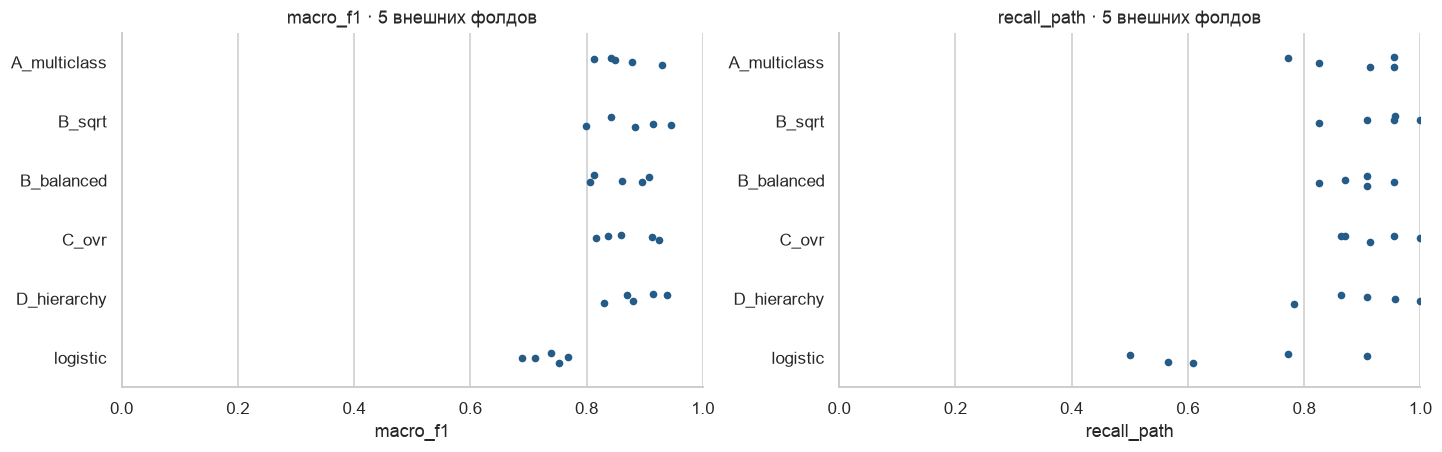

In [13]:
selected = folds.merge(best[['family','mode']], on=['family','mode'])
fig, axes = plt.subplots(1,2,figsize=(13,4),constrained_layout=True)
for ax,metric in zip(axes,['macro_f1','recall_path']):
    sns.stripplot(data=selected,x=metric,y='family',color='#245b87',jitter=.10,ax=ax)
    ax.set(title=f'{metric} · 5 внешних фолдов',xlim=(0,1),ylabel='')
plt.show()
print('Фолды имеют пересекающиеся train, поэтому точки не являются 5 независимыми испытаниями.')

### Найденные параметры и выбранное семейство

In [15]:
parameters = pd.DataFrame(json.loads((OUT / 'nested_parameters.json').read_text()))
display(parameters)
selection = json.loads((OUT / 'nested_selection.json').read_text())
print('Зафиксировано семейство:', selection['family'], '· pooled macro-F1:', round(selection['pooled_macro_f1'],4))

Зафиксировано семейство: D_hierarchy · pooled macro-F1: 0.8846


,family,outer_fold,params,threshold
0,A_multiclass,0,"{'depth': 3, 'iterations': 600, 'l2_leaf_reg':...",0.50
1,B_sqrt,0,"{'depth': 3, 'iterations': 600, 'l2_leaf_reg':...",NaN
2,B_balanced,0,"{'depth': 3, 'iterations': 600, 'l2_leaf_reg':...",0.25
3,C_ovr,0,"{'depth': 3, 'iterations': 300, 'l2_leaf_reg':...",0.30
4,D_hierarchy,0,"{'depth': 3, 'iterations': 600, 'l2_leaf_reg':...",0.35
5,logistic,0,"{'C': 10.0, 'class_weight': None}",0.40
6,A_multiclass,1,"{'depth': 5, 'iterations': 600, 'l2_leaf_reg':...",0.55
7,B_sqrt,1,"{'depth': 3, 'iterations': 300, 'l2_leaf_reg':...",0.25
8,B_balanced,1,"{'depth': 3, 'iterations': 300, 'l2_leaf_reg':...",0.40
9,C_ovr,1,"{'depth': 3, 'iterations': 600, 'l2_leaf_reg':...",0.50


## Выводы
Семейство выбрано по внешним OOF-предсказаниям исходного train. Сетка обеспечивает сравнение 24 заданных комбинаций, но не доказывает глобальный оптимум. Выбор среди процедур делает результат победителя несколько оптимистичным; 03 проверяет его на test после калибровки и проверки fold averaging. Большой macro-F1 не заменяет анализа патологических ошибок и вероятностей.